## 1. Preparar el entorno

Se clona la rama `implementacionRedesNeuronales`, que tiene el código. Después se comprueba que la sesión tenga una GPU. Si `nvidia-smi` muestra una Tesla T4, se puede entrenar.

Luego se monta Google Drive y se copian las imágenes desde la carpeta `ia/TP2/data`, que tiene el dataset CCSN ya dividido en entrenamiento (1.525), validación (509) y prueba (509). Como la carpeta es compartida, antes hay que agregarla a Mi unidad: clic derecho en `ia` → Organizar → Agregar acceso directo a Mi unidad.

In [1]:
!git clone -b implementacionRedesNeuronales https://github.com/GianfrancoRiccelli/TP2_Sistemas_Inteligentes.git
%cd TP2_Sistemas_Inteligentes
!nvidia-smi

Cloning into 'TP2_Sistemas_Inteligentes'...
remote: Enumerating objects: 2625, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 2625 (delta 7), reused 37 (delta 6), pack-reused 2585 (from 4)
Receiving objects: 100% (2625/2625), 92.97 MiB | 23.59 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/TP2_Sistemas_Inteligentes
Sat Oct 24 17:23:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|===================

In [2]:
# Conexión con Google Drive.
# Las imágenes del dataset CCSN, ya divididas en train / val / test, están en
# la carpeta "ia/TP2/data" del Drive del grupo. Como es una carpeta compartida,
# antes hay que agregarla a Mi unidad: clic derecho en "ia" -> Organizar ->
# Agregar acceso directo a Mi unidad. Si la carpeta está en otro lugar,
# cambiar solo RUTA_DRIVE.
from google.colab import drive
drive.mount('/content/drive')

RUTA_DRIVE = '/content/drive/MyDrive/ia/TP2/data'

# Se reemplazan las imágenes del repo por las del Drive
!rm -rf data/train data/val data/test
!cp -r "{RUTA_DRIVE}/train" "{RUTA_DRIVE}/val" "{RUTA_DRIVE}/test" data/

# Control: tiene que dar 1525, 509 y 509
!for c in train val test; do echo "$c: $(find data/$c -iname '*.jpg' | wc -l)"; done

Mounted at /content/drive
train: 1525
val: 509
test: 509


## 2. Probar el MLP

Primera corrida, solo para ver que los datos se leen y que la red entrena. Usa el conjunto de validación para cortar el entrenamiento. El conjunto de prueba no se mira. Los resultados quedan en `results/mlp`.

In [ ]:
!python src/mlp.py

I0000 00:00:1792855246.648637    7922 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 1525 files belonging to 11 classes.
W0000 00:00:1792855253.779505    7922 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792855253.781257    7922 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Found 509 files belonging to 11 classes.
Found 509 files belonging to 11 classes.
Epoch 1/100
I0000 00:00:1792855258.309400    7972 service.cc:153] XLA service 0x7a78f00330a0 initialized for platform CUDA (this does not guarantee that XLA wi

## 3. MLP para el informe

Misma red que la prueba anterior. Ahora se miden el conjunto de entrenamiento y el de prueba. El corte del entrenamiento sigue haciéndose con la validación.

In [ ]:
!python src/mlp.py --final

I0000 00:00:1792855608.925325   11028 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 1525 files belonging to 11 classes.
W0000 00:00:1792855614.024560   11028 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792855614.026373   11028 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Found 509 files belonging to 11 classes.
Found 509 files belonging to 11 classes.
Epoch 1/100
I0000 00:00:1792855618.026443   11073 service.cc:153] XLA service 0x7f56540409e0 initialized for platform CUDA (this does not guarantee that XLA wi

## 4. ConvNet desde cero
Red convolucional entrenada desde el inicio, con imágenes de 256×256. Es la corrida más larga.

In [ ]:
!python src/cnn.py --final

I0000 00:00:1792856161.794917   14157 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 1525 files belonging to 11 classes.
W0000 00:00:1792856167.099157   14157 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792856167.100934   14157 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Found 509 files belonging to 11 classes.
Found 509 files belonging to 11 classes.
Epoch 1/100
I0000 00:00:1792856172.238339   14206 service.cc:153] XLA service 0x7a0cac0361e0 initialized for platform CUDA (this does not guarantee that XLA wi

## 5. ConvNet preentrenada

MobileNetV2, ya entrenada con ImageNet. Solo se entrena la capa final de 11 clases. La primera vez descarga esos pesos.

In [ ]:
!python src/cnn_preentrenada.py --final

I0000 00:00:1792856385.098279   15951 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 1525 files belonging to 11 classes.
W0000 00:00:1792856390.245683   15951 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792856390.247557   15951 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Found 509 files belonging to 11 classes.
Found 509 files belonging to 11 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
I0000 00:00:1792856398.762701   15996 service.cc:153] XLA service 0x7da59005f0f0 initialized for pl

## 6. ConvNet preentrenada con ajuste fino y aumento de datos

Cuarta corrida. Parte de la misma MobileNetV2 de la sección 5, con dos cambios para reducir el sobreajuste que se vio ahí (71,9 % en entrenamiento contra 40,1 % en prueba): aumento de datos (en cada época las fotos de entrenamiento se espejan, rotan, acercan y cambian de contraste al azar) y ajuste fino de las últimas 40 capas de la red con un learning rate de 0,0001. Los resultados quedan en `results/cnn_finetuning`.

In [7]:
%%writefile src/cnn_finetuning.py
"""ConvNet preentrenada con ajuste fino y aumento de datos.

Parte de la misma MobileNetV2 de ImageNet que cnn_preentrenada.py, con dos cambios
para atacar el sobreajuste que se vio en esa corrida (72 % en entrenamiento contra
40 % en prueba):

1. Aumento de datos: en cada época las fotos de entrenamiento se espejan, rotan,
   acercan y cambian de contraste al azar, así la red no ve dos veces la misma imagen.
   Estas capas solo actúan al entrenar; en la evaluación las imágenes pasan sin cambios.
2. Ajuste fino: además de la capa de salida, se entrenan las últimas capas de
   MobileNetV2 con un learning rate bajo, para adaptar sus filtros a texturas de nubes.

Uso (desde la raíz del repo):
    python src/cnn_finetuning.py           # evalúa entrenamiento y validación
    python src/cnn_finetuning.py --final   # evalúa entrenamiento y prueba, una sola vez
"""

import argparse
import sys

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

from config import CLASES, SEED
from utils import cargar_conjuntos, entrenar, evaluar, fijar_semillas

NOMBRE = "cnn_finetuning"  # carpeta de salida: results/cnn_finetuning
TAMANIO = (224, 224)  # tamaño de entrada con el que se entrenó MobileNetV2
BATCH_SIZE = 32
EPOCAS = 50
PACIENCIA = 8
# Bajo a propósito: más alto rompería los filtros que ya trae la red de ImageNet.
LEARNING_RATE = 1e-4
CAPAS_ENTRENABLES = 40  # últimas capas de MobileNetV2 que se descongelan


def aumento_de_datos():
    """Transformaciones al azar que solo se aplican durante el entrenamiento.

    Solo espejado horizontal: dar vuelta una foto de cielo de arriba abajo
    deja el horizonte arriba, algo que no pasa en fotos reales.
    """
    return tf.keras.Sequential(
        [
            tf.keras.layers.RandomFlip("horizontal", seed=SEED),
            tf.keras.layers.RandomRotation(0.05, seed=SEED),  # hasta unos 18 grados
            tf.keras.layers.RandomZoom(0.15, seed=SEED),
            tf.keras.layers.RandomContrast(0.2, value_range=(-1, 1), seed=SEED),
        ],
        name="aumento_de_datos",
    )


def construir():
    """Arma la red: aumento de datos, MobileNetV2 parcialmente descongelada y salida de 11 clases."""
    fijar_semillas()
    base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(*TAMANIO, 3))
    base.trainable = True
    # Se congelan todas menos las últimas CAPAS_ENTRENABLES. Las primeras detectan
    # bordes y texturas generales, que sirven igual para nubes.
    for capa in base.layers[:-CAPAS_ENTRENABLES]:
        capa.trainable = False
    # Las capas de normalización por lotes quedan congeladas siempre. Si se entrenan,
    # usan las estadísticas del lote al entrenar y las de ImageNet al evaluar, y la red
    # se comporta distinto en cada caso (en Keras 3 no alcanza con training=False).
    for capa in base.layers:
        if isinstance(capa, tf.keras.layers.BatchNormalization):
            capa.trainable = False

    entrada = tf.keras.Input(shape=(*TAMANIO, 3))
    x = aumento_de_datos()(entrada)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    salida = tf.keras.layers.Dense(len(CLASES), activation="softmax")(x)

    modelo = tf.keras.Model(entrada, salida, name=NOMBRE)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


def main():
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument(
        "--final",
        action="store_true",
        help="evalúa entrenamiento y prueba; sin este flag, entrenamiento y validación",
    )
    args = parser.parse_args()
    conjuntos_eval = ("train", "test") if args.final else ("train", "val")

    # preprocess_input escala a [-1, 1], que es lo que espera MobileNetV2.
    conjuntos = cargar_conjuntos(
        tamanio=TAMANIO,
        batch_size=BATCH_SIZE,
        preprocesar=preprocess_input,
    )
    modelo = construir()
    historial = entrenar(
        modelo,
        conjuntos,
        NOMBRE,
        epocas=EPOCAS,
        paciencia=PACIENCIA,
        parametros={
            "tamaño de imagen": f"{TAMANIO[0]}x{TAMANIO[1]}",
            "batch size": BATCH_SIZE,
            "backbone": f"MobileNetV2 ImageNet, últimas {CAPAS_ENTRENABLES} capas entrenables",
            "aumento de datos": "espejado horizontal, rotación 5 %, zoom 15 %, contraste 20 %",
            "dropout antes de la salida": 0.3,
            "evaluación": "/".join(conjuntos_eval),
        },
    )
    evaluar(modelo, conjuntos, historial, NOMBRE, conjuntos_eval=conjuntos_eval)
    return 0


if __name__ == "__main__":
    sys.exit(main())

Overwriting src/cnn_finetuning.py


In [8]:
%cd /content/TP2_Sistemas_Inteligentes
!python src/cnn_finetuning.py --final

/content/TP2_Sistemas_Inteligentes
I0000 00:00:1792865137.124120   17990 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 1525 files belonging to 11 classes.
W0000 00:00:1792865141.793478   17990 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792865141.795247   17990 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
Found 509 files belonging to 11 classes.
Found 509 files belonging to 11 classes.
Epoch 1/50
I0000 00:00:1792865155.662867   18031 cuda_dnn.cc:461] Loaded cuDNN version 92700
48/48 - 17s - 351ms/step - accu

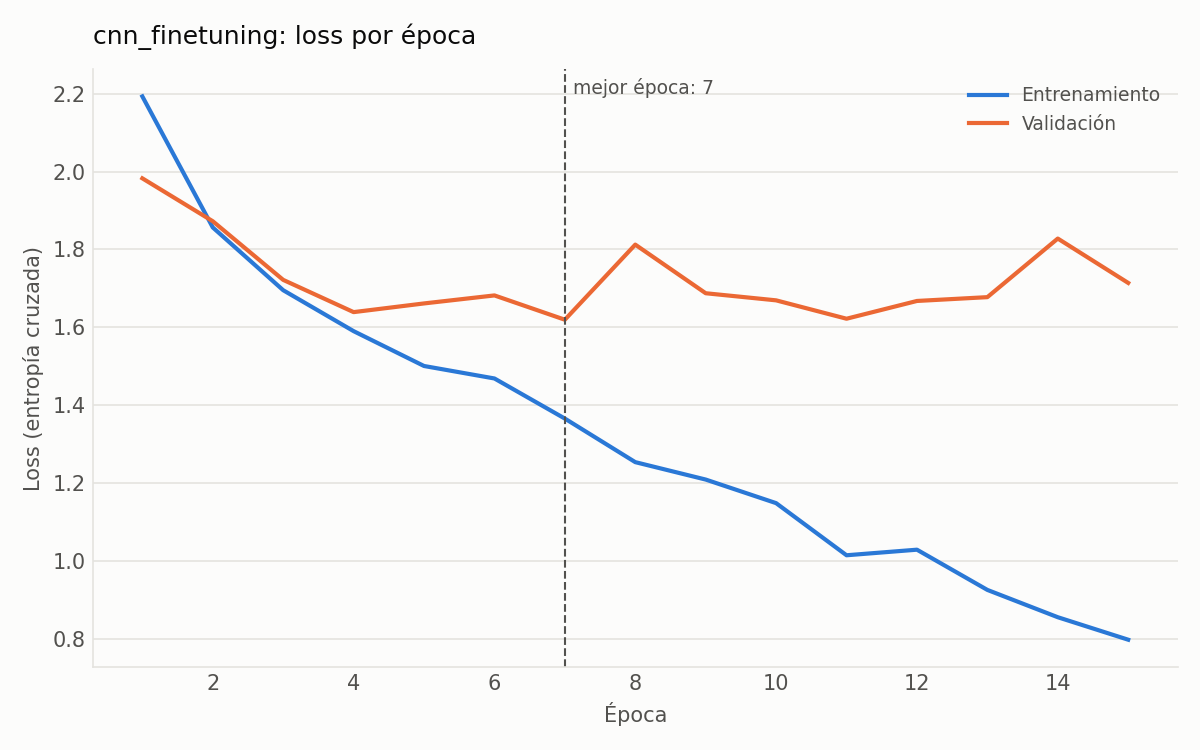

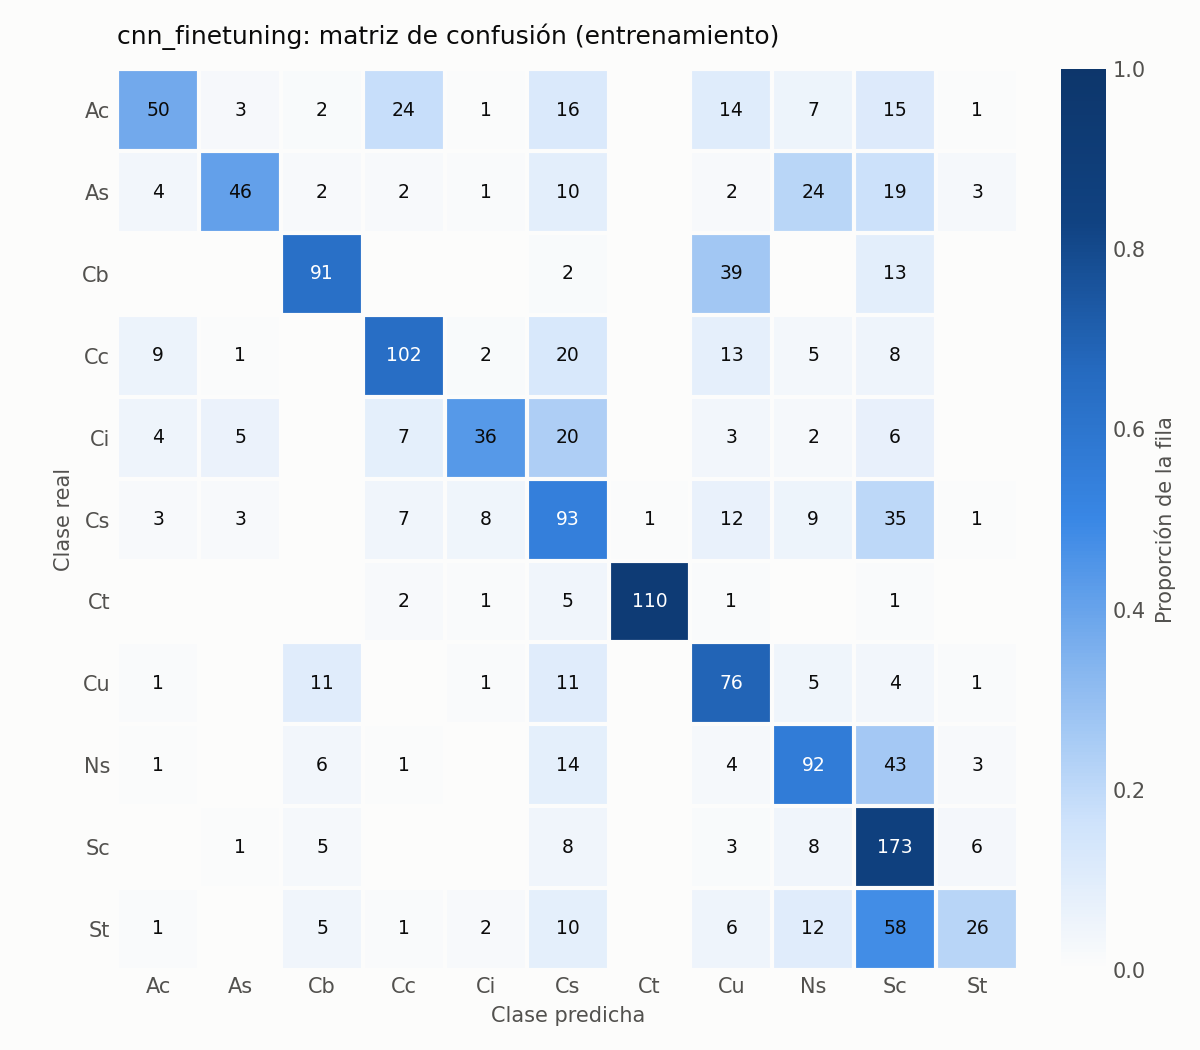

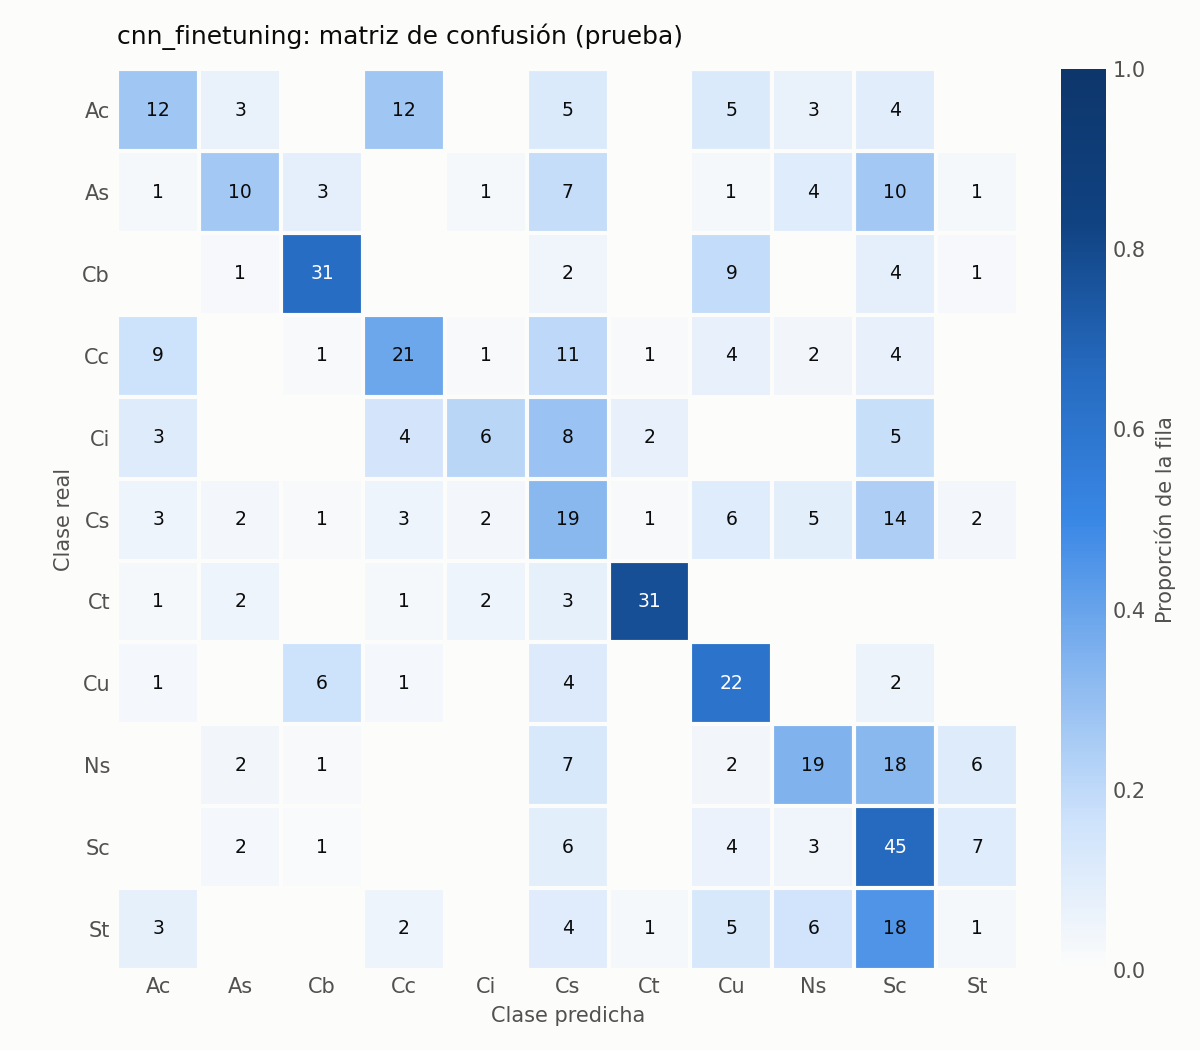

In [9]:
from IPython.display import Image, display
for archivo in ("loss.png", "cm_train.png", "cm_test.png"):
    display(Image(f"results/cnn_finetuning/{archivo}"))

## 7. Comparación

Exactitud de cada red en la corrida final. El corte del entrenamiento se hizo con la validación. Estas cifras son sobre los datos de entrenamiento y de prueba.

| Modelo | Entrenamiento | Prueba | Diferencia |
|---|---:|---:|---:|
| MLP | 22,6 % | 21,8 % | 0,8 |
| ConvNet desde cero | 42,8 % | 31,6 % | 11,2 |
| MobileNetV2 preentrenada (base congelada) | 71,9 % | 40,1 % | 31,8 |
| MobileNetV2 con ajuste fino y aumento de datos | 58,7 % | 42,6 % | 16,1 |

Elegir una clase al azar acierta cerca del 9 %. Las cuatro lo superan. La red con ajuste fino es la que mejor clasifica fotos nuevas (42,6 %), aunque supera a la preentrenada congelada por solo 2,5 puntos, unas 13 imágenes de las 509 de prueba. La diferencia más importante entre esas dos es otra: la distancia entre entrenamiento y prueba bajó de 31,8 a 16,1 puntos, así que la red con aumento de datos memoriza menos las fotos con las que aprende.

## 8. Guardar los resultados

Colab borra los archivos al cerrar la sesión. Se comprime la carpeta `results` (curvas de error, matrices de confusión y métricas de las cuatro redes) y se descarga.

In [10]:
%cd /content/TP2_Sistemas_Inteligentes
!zip -r resultados.zip results
from google.colab import files
files.download("resultados.zip")

/content/TP2_Sistemas_Inteligentes
  adding: results/ (stored 0%)
  adding: results/cnn_desde_cero/ (stored 0%)
  adding: results/cnn_desde_cero/loss.png (deflated 7%)
  adding: results/cnn_desde_cero/config.txt (deflated 85%)
  adding: results/cnn_desde_cero/cm_test.png (deflated 11%)
  adding: results/cnn_desde_cero/cm_train.png (deflated 10%)
  adding: results/cnn_desde_cero/metricas_train.csv (deflated 39%)
  adding: results/cnn_desde_cero/metricas_test.csv (deflated 41%)
  adding: results/cnn_desde_cero/historial.csv (deflated 50%)
  adding: results/mlp/ (stored 0%)
  adding: results/mlp/loss.png (deflated 7%)
  adding: results/mlp/config.txt (deflated 76%)
  adding: results/mlp/cm_test.png (deflated 13%)
  adding: results/mlp/cm_train.png (deflated 11%)
  adding: results/mlp/metricas_train.csv (deflated 45%)
  adding: results/mlp/metricas_test.csv (deflated 46%)
  adding: results/mlp/historial.csv (deflated 54%)
  adding: results/cnn_finetuning/ (stored 0%)
  adding: results/cnn_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusión

La red que mejor resuelve el problema es la MobileNetV2 con ajuste fino y aumento de datos: en fotos que no vio durante el entrenamiento acierta el 42,6 %. La preentrenada con la base congelada llega al 40,1 %, la convolucional desde cero al 31,6 % y el MLP al 21,8 %. Elegir una clase al azar ronda el 9 %.

El MLP aplana la imagen y no usa la forma de la nube. En la prueba casi solo responde estratocúmulo o cirrocúmulo, y deja varias clases en cero.

La convolucional desde cero sí usa la imagen. Aprende, pero a partir de la época 7 el error de entrenamiento sigue bajando y el de validación sube: empieza a memorizar las fotos de entrenamiento. Por eso el modelo guardado es el de esa época.

La preentrenada parte de filtros ya entrenados para ver bordes y texturas, y con pocas épocas llega más lejos. Con la base congelada, en el entrenamiento acierta el 71,9 % y en la prueba el 40,1 %. Al sumar aumento de datos y entrenar también sus últimas 40 capas, la prueba sube apenas, al 42,6 %, pero la diferencia con el entrenamiento se reduce a la mitad.

En las cuatro redes, las confusiones que quedan son entre nubes parecidas: el estrato con el estratocúmulo (en la mejor red, 18 de los 40 estratos de prueba se clasifican como estratocúmulo y solo 1 se acierta), el nimbostrato con el estratocúmulo y el altocúmulo con el cirrocúmulo. La estela de avión y el cumulonimbo, que se ven distintos del resto, son las clases que mejor se detectan.

Ninguna de las cuatro redes resuelve el problema de forma satisfactoria: acertar menos de la mitad de las fotos nuevas no alcanza para reemplazar a un observador entrenado.

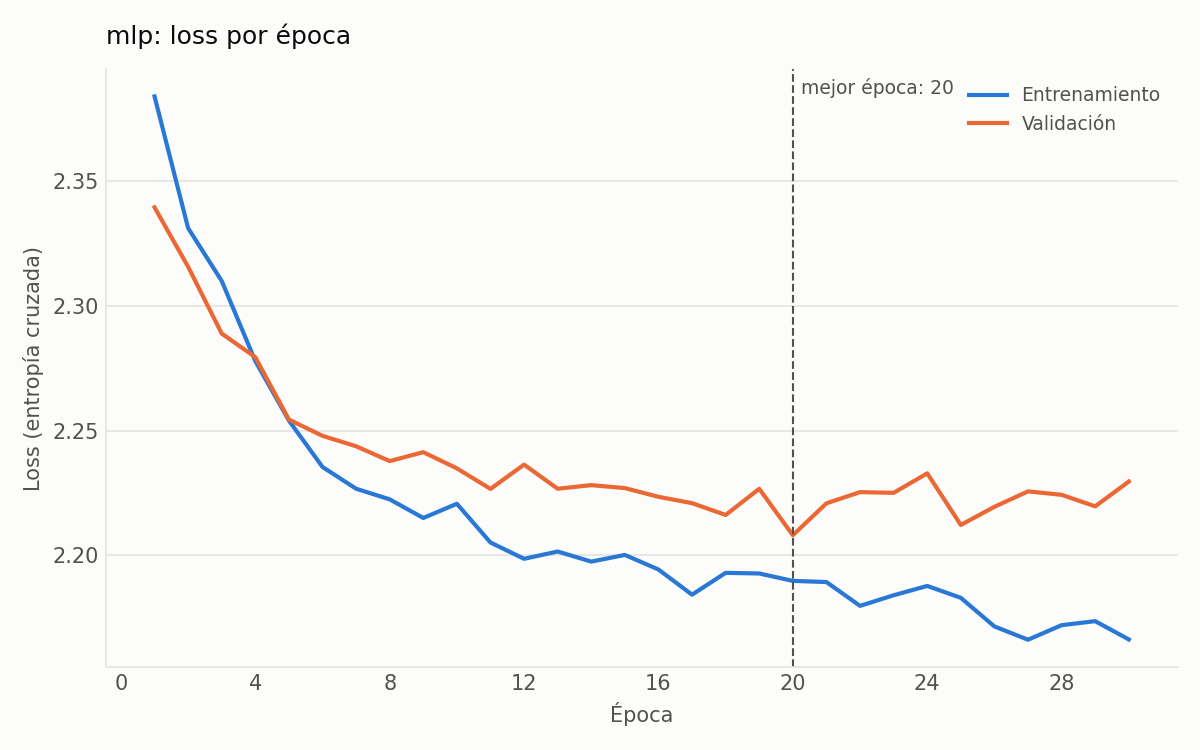

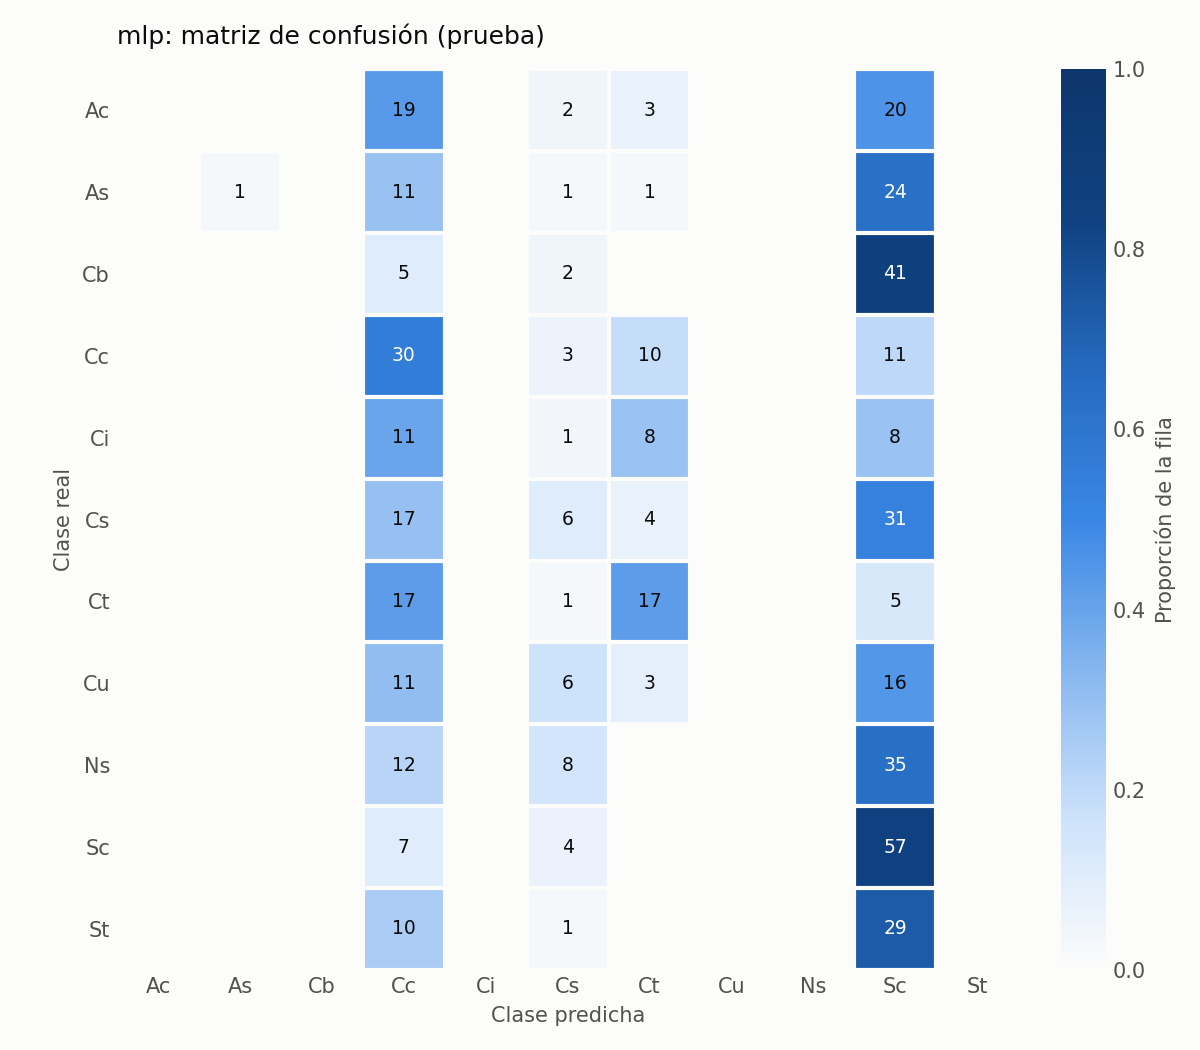

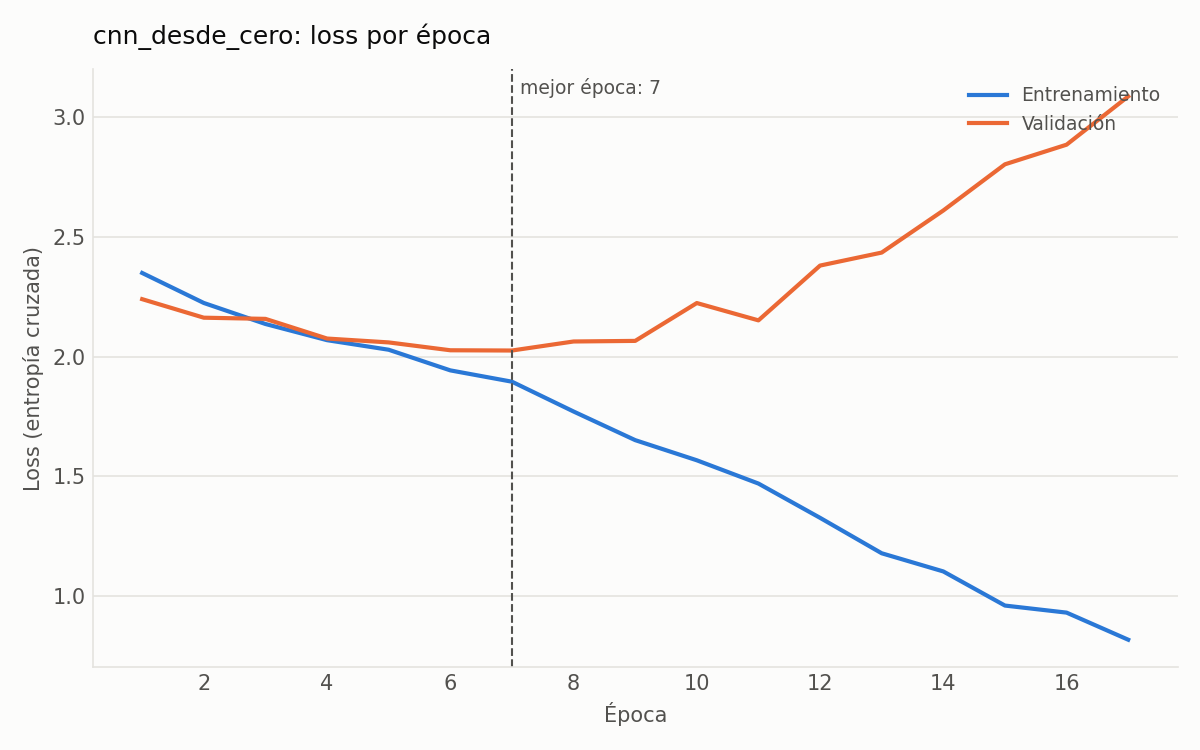

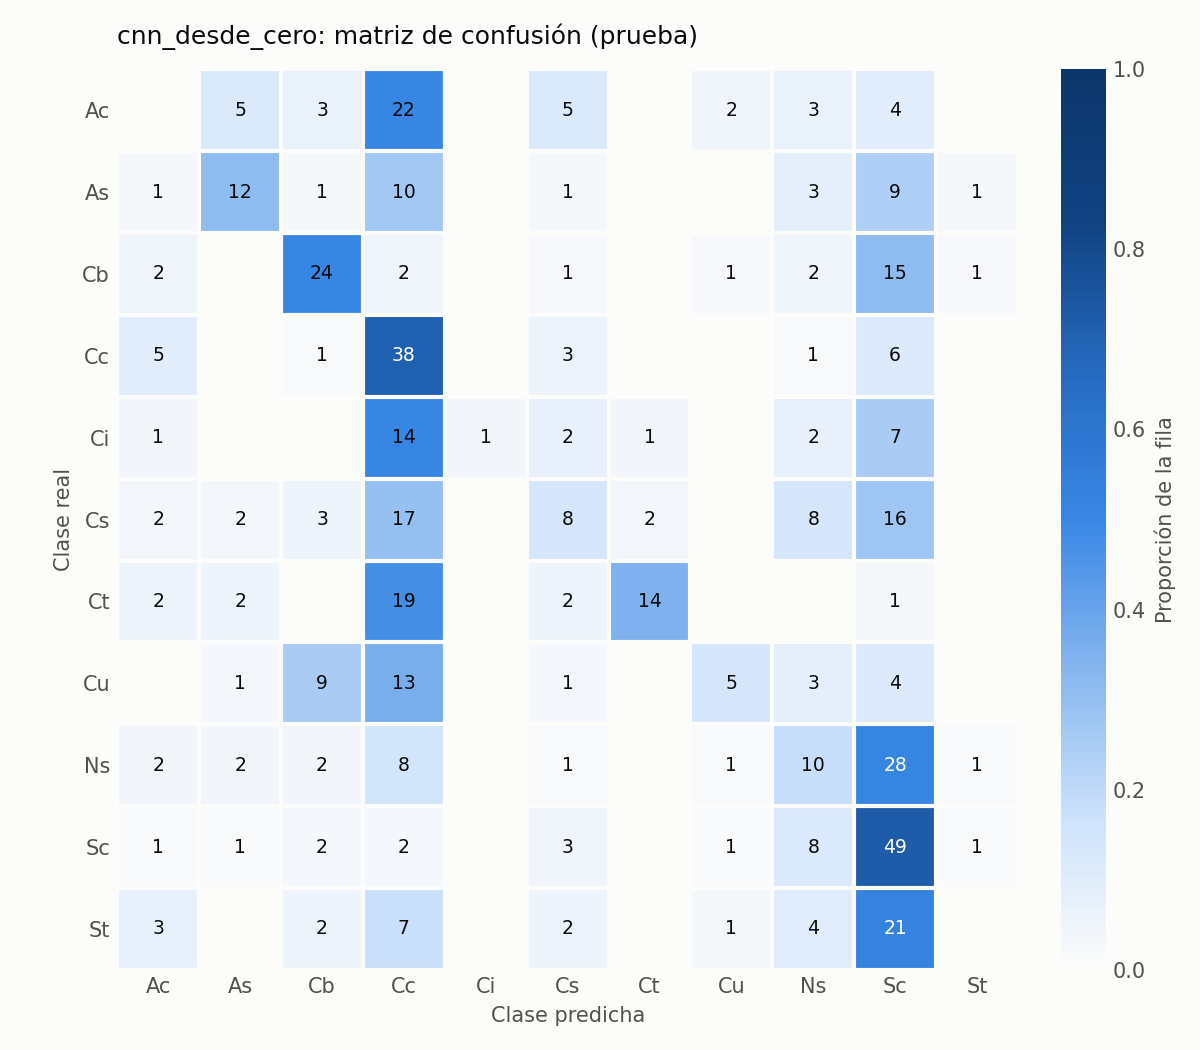

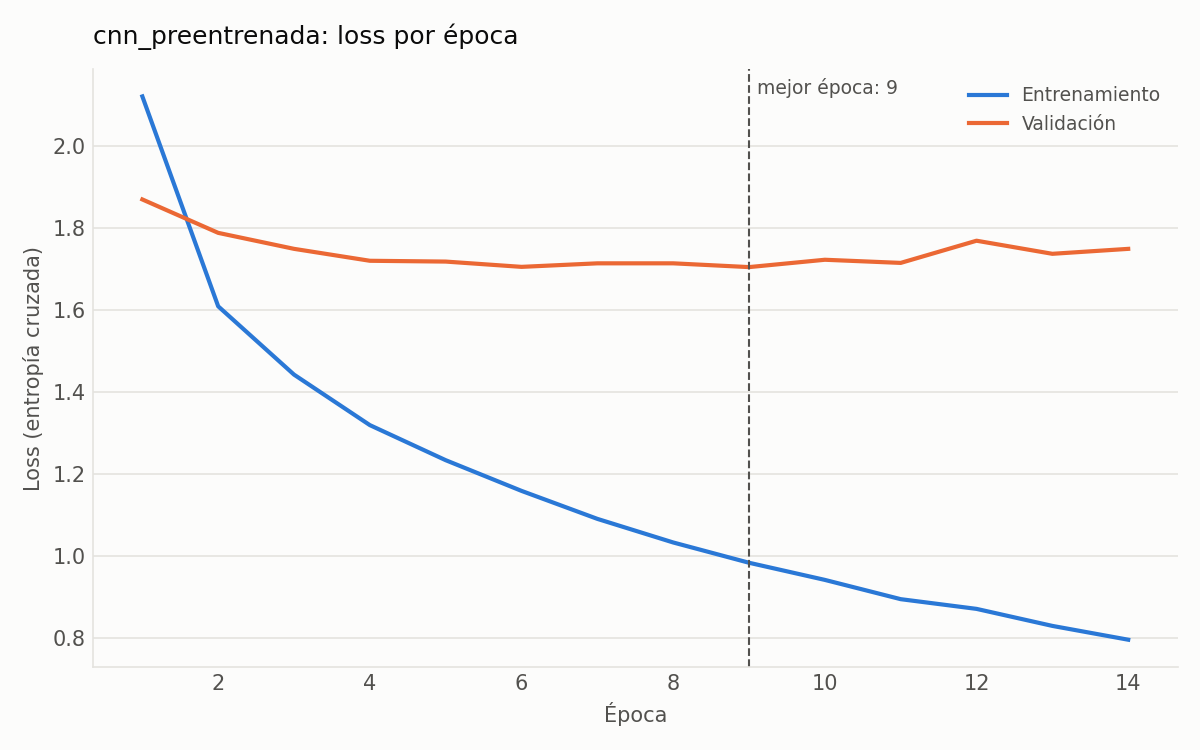

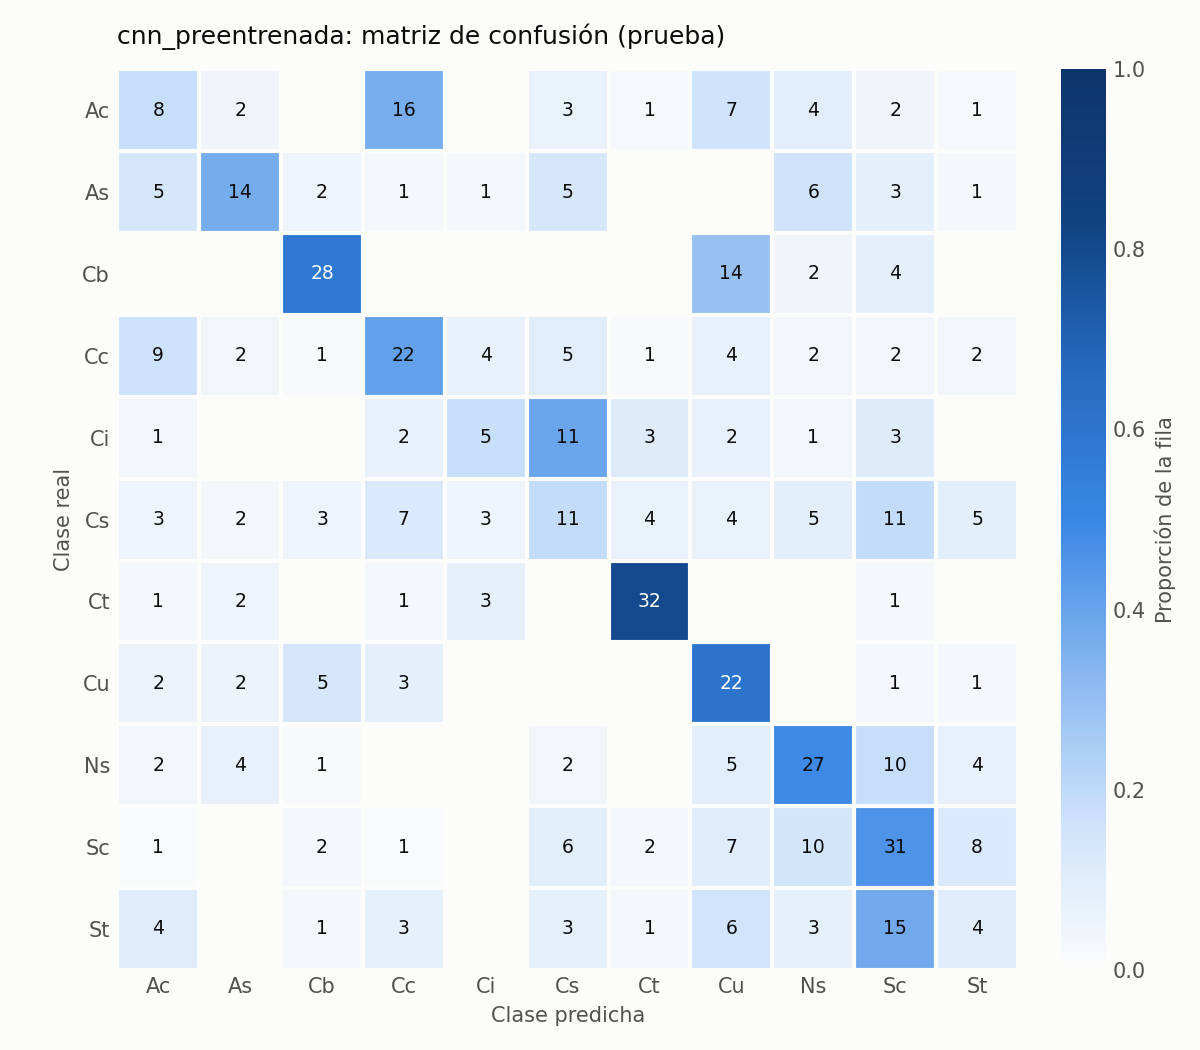

In [ ]:
from IPython.display import Image, display

for modelo in ("mlp", "cnn_desde_cero", "cnn_preentrenada"):
    display(Image(f"results/{modelo}/loss.png"))
    display(Image(f"results/{modelo}/cm_test.png"))

## 10. Qué se desprende de las curvas

El orden de los resultados es el esperado. El MLP no usa la forma de la nube y se queda cerca del 22 %. La convolucional desde cero mejora, pero en la curva se ve que después de la época 7 el error de entrenamiento sigue bajando y el de validación sube: memoriza las fotos. La preentrenada llega al 40,1 % en la prueba porque reutiliza filtros ya aprendidos.

La cuarta corrida probó las mejoras más directas para ese sobreajuste: aumentar las imágenes de entrenamiento (volteos, rotación, zoom y contraste) y entrenar también las últimas capas de MobileNetV2 con un learning rate diez veces más bajo. En su curva, el error de validación baja hasta la época 7 y después oscila entre 1,62 y 1,83 mientras el de entrenamiento sigue bajando. El sobreajuste se redujo, pero no desapareció, y la exactitud en la prueba mejoró poco.

Ese 42,6 % todavía está lejos de CloudNet, la red del paper de este mismo dataset, que informa un promedio cercano al 88 %. Lo que queda por probar es dar más peso a las clases con menos fotos (como el cirro) y usar una arquitectura más grande. Las confusiones entre estrato y estratocúmulo, nimbostrato y estratocúmulo, o altocúmulo y cirrocúmulo son de nubes parecidas a simple vista, y no se corrigen solo con más épocas.

El límite principal es la cantidad de datos: hay 1.525 imágenes de entrenamiento para 11 clases, unas 140 por clase. Con más fotos reales de cada tipo de nube los resultados mejorarían. El aumento de datos imita parte de ese efecto, pero, como muestra la cuarta corrida, no lo reemplaza.